# 0a_04 Conditional Probability and Independence: Probability After You Learn Something

**Learning objectives**
- Define **conditional probability** $P(A\mid B)$ and compute it from a table, from counting, or from the formula $P(A\cap B)/P(B)$.
- Use the **general multiplication rule** $P(A\cap B)=P(B)\,P(A\mid B)$, in particular for draws **without replacement**.
- Test **independence** with $P(A\mid B)=P(A)$ and see it in a contingency table.
- Avoid the classic traps: confusing $P(A\mid B)$ with $P(B\mid A)$, the **two-children** problem and **Monty Hall**.

**Prerequisites:** [0a_03 The rules of probability](0a_03_probability_rules.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools
from matplotlib.patches import Rectangle

## 2. Prerequisite recap

- $P(A\cap B)$ is the probability that **both** events happen; $P(A\cup B)$ that at least one does (0a_03).
- Events are **independent** if $P(A\cap B)=P(A)P(B)$.
- With equally likely outcomes, $P(A)=|A|/|S|$ (0a_01 and 0a_02).
- A **contingency table** counts people by two categories at once (rows and columns).

## 3. Intuition and story

Probabilities change when we learn something. The chance that a random card is an ace is $4/52$. If we are told it is a **face card or an ace** the chance changes; if we are told it is a **heart**, it changes again (to $1/13$, the same as before: learning "heart" tells us nothing about being an ace). **Conditional probability** $P(A\mid B)$, read "the probability of $A$ given $B$", is the probability of $A$ *in the smaller world where $B$ is known to have happened*.

The picture to keep in mind: **shrink the sample space to $B$**, then ask what fraction of $B$ is also in $A$. Everything else (independence, Bayes' theorem in 0a_05 and Module 00) is built on that one idea.

## 4. Formal definitions

**Conditional probability.** For $P(B)>0$,
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}.$$
With equally likely outcomes this is $\dfrac{|A\cap B|}{|B|}$: count inside $B$ only.

**General multiplication rule.** $P(A\cap B)=P(B)\,P(A\mid B)=P(A)\,P(B\mid A)$. For a chain: $P(A_1\cap A_2\cap A_3)=P(A_1)\,P(A_2\mid A_1)\,P(A_3\mid A_1\cap A_2)$.

**Independence.** $A$ and $B$ are independent if and only if $P(A\mid B)=P(A)$ (equivalently $P(B\mid A)=P(B)$, or $P(A\cap B)=P(A)P(B)$): knowing $B$ does not change the chance of $A$.

**Complement inside a condition.** $P(A^c\mid B)=1-P(A\mid B)$: conditional probabilities obey all the usual rules of probability *inside the world $B$*.

**Contingency table.** For categories with joint counts $n_{ij}$ (row $i$, column $j$) and total $n$: $P(\text{row }i\mid\text{column }j)=n_{ij}/n_{\cdot j}$. Independence means every row of conditional probabilities is identical.

## 5. Derivations

### 5.1 The definition from counting
Suppose $N$ equally likely outcomes, $|B|$ of them in $B$ and $|A\cap B|$ in both. Once we know $B$ happened, only the $|B|$ outcomes in $B$ remain possible and they are still equally likely, so $P(A\mid B)=\dfrac{|A\cap B|}{|B|}=\dfrac{|A\cap B|/N}{|B|/N}=\dfrac{P(A\cap B)}{P(B)}$. **In plain words.** Shrink the world to $B$, then take the fraction of that smaller world that is in $A$.

### 5.2 The multiplication rule
Multiply the definition by $P(B)$: $P(A\cap B)=P(B)P(A\mid B)$. **In plain words.** "A and B" means B happens first (probability $P(B)$) and then A happens in the world where B did.

### 5.3 Draws without replacement
Two aces from a deck: $P(\text{ace}_1\cap\text{ace}_2)=P(\text{ace}_1)\,P(\text{ace}_2\mid\text{ace}_1)=\dfrac4{52}\cdot\dfrac3{51}=\dfrac1{221}$. The second probability is *not* $4/52$ because one ace is gone from the deck. **In plain words.** Each draw changes what is left, so the draws are dependent; with replacement they would be independent and the answer would be $(4/52)^2$.

### 5.4 Independence in three equivalent forms
If $P(A\cap B)=P(A)P(B)$ and $P(B)>0$, then $P(A\mid B)=P(A)P(B)/P(B)=P(A)$. The converse is the same line read backwards. **In plain words.** If knowing $B$ never moves the probability of $A$, then the joint chance is the product.

### 5.5 $P(A\mid B)\neq P(B\mid A)$
Both equal $P(A\cap B)$ divided by different totals: $P(A\mid B)=P(A\cap B)/P(B)$ and $P(B\mid A)=P(A\cap B)/P(A)$. They are equal only when $P(A)=P(B)$. **In plain words.** "Most mobile visitors do not buy" and "most buyers are on mobile" are different statements; mixing them up is the commonest error in probability (and the reason for Bayes' theorem).

## 6. Properties and relationships

- **Conditioning is probability in a smaller world:** $P(\cdot\mid B)$ satisfies the axioms, so complement and addition rules hold inside $B$.
- **Independent events carry no information about each other;** dependent events do, positively ($P(A\mid B)>P(A)$) or negatively ($P(A\mid B)<P(A)$).
- **Mutually exclusive events are dependent:** $P(A\mid B)=0\ne P(A)$.
- **Bayes' theorem (0a_05, Module 00):** $P(A\mid B)=P(B\mid A)P(A)/P(B)$ reverses a conditional probability.
- **Looking ahead:** conditional distributions of random variables (00_03) and the conditional mean are the same idea with numbers instead of events; **Markov chains**, **naive Bayes** and **autoregressive models** all multiply conditionals.

## 7. 2D visuals

### 7.1 Shrinking the sample space
Two dice. Left: all 36 outcomes with $A$ = "sum is 8" in blue. Right: after learning $B$ = "at least one six" only the 11 outcomes of $B$ remain; the blue outcomes inside $B$ are 2, so $P(A\mid B)=2/11$, not $P(A)=5/36$.

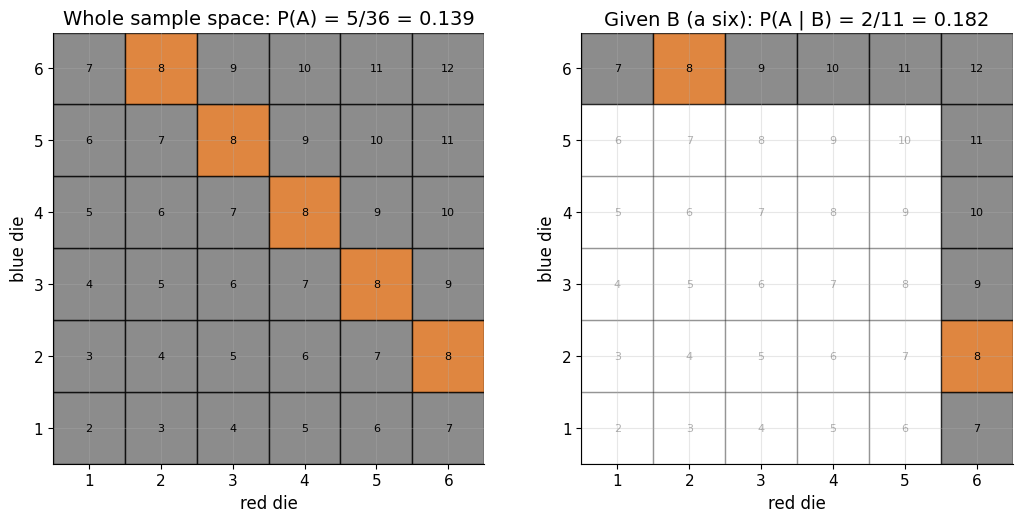

In [2]:
S = list(itertools.product(range(1, 7), range(1, 7)))
A = {o for o in S if sum(o) == 8}; B = {o for o in S if 6 in o}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
for ax, universe, title in [(axes[0], set(S), f"Whole sample space: P(A) = {len(A)}/36 = {len(A) / 36:.3f}"), (axes[1], B, f"Given B (a six): P(A | B) = {len(A & B)}/{len(B)} = {len(A & B) / len(B):.3f}")]:
    for r, b in S:
        in_u = (r, b) in universe
        col = (HIGHLIGHT if (r, b) in A else SIM) if in_u else "white"
        if in_u and (r, b) not in A: col = NEUTRAL
        ax.add_patch(Rectangle((r - 0.5, b - 0.5), 1, 1, facecolor=col, edgecolor="black", alpha=0.75 if in_u else 0.25))
        ax.text(r, b, f"{r + b}", ha="center", va="center", fontsize=8, alpha=1 if in_u else 0.3)
    ax.set_xlim(0.5, 6.5); ax.set_ylim(0.5, 6.5); ax.set_aspect("equal"); ax.set_title(title); ax.set_xlabel("red die"); ax.set_ylabel("blue die")
plt.show()
assert np.isclose(len(A & B) / len(B), 2 / 11) and np.isclose(len(A) / 36, 5 / 36)

### 7.2 A contingency table: online visitors by device and purchase
A store logged 10,000 visits. The joint table drives every conditional probability. Rows: device; columns: bought or not.

         bought  did not buy  total
mobile      180         5820   6000
desktop     240         2760   3000
tablet       50          950   1000
column totals: {'bought': 470, 'did not buy': 9530, 'total': 10000}


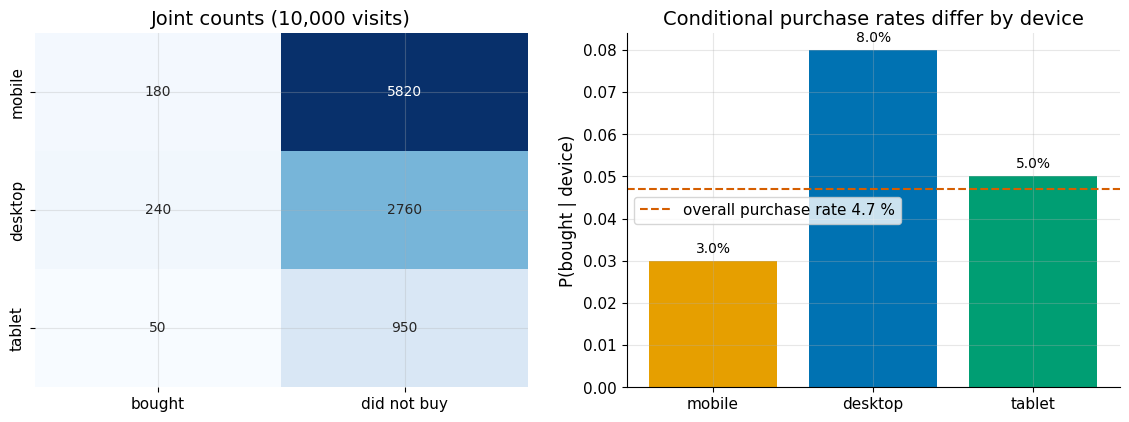

In [3]:
table = pd.DataFrame({"bought": [180, 240, 50], "did not buy": [5820, 2760, 950]}, index=["mobile", "desktop", "tablet"])
table["total"] = table.sum(axis=1)
print(table.to_string()); print("column totals:", table.sum().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(table[["bought", "did not buy"]], annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title("Joint counts (10,000 visits)")
rates = table["bought"] / table["total"]
axes[1].bar(rates.index, rates.values, color=[SIM, MAIN, COLORS[2]]); axes[1].axhline(470 / 10000, color=HIGHLIGHT, linestyle="--", label="overall purchase rate 4.7 %")
for i_, v_ in enumerate(rates.values): axes[1].text(i_, v_ + 0.002, f"{v_:.1%}", ha="center")
axes[1].set_ylabel("P(bought | device)"); axes[1].set_title("Conditional purchase rates differ by device"); axes[1].legend()
plt.show()

### 7.3 Mosaic view: widths show the device mix, heights the purchase rate
Each rectangle's area is the joint probability $P(\text{device}\cap\text{bought})$ (the shaded part). If device and purchase were independent all the shaded heights would be equal.

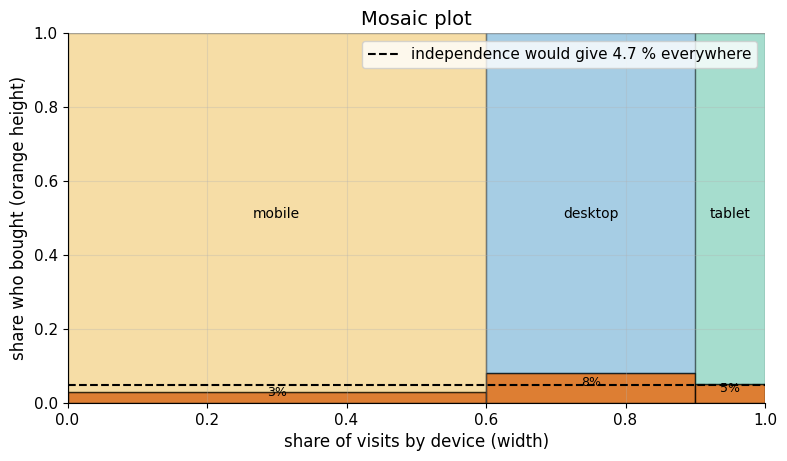

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x0 = 0
for dev, col in zip(table.index, [SIM, MAIN, COLORS[2]]):
    w = table.loc[dev, "total"] / 10000; h = table.loc[dev, "bought"] / table.loc[dev, "total"]
    ax.add_patch(Rectangle((x0, 0), w, h, facecolor=HIGHLIGHT, edgecolor="black", alpha=0.8))
    ax.add_patch(Rectangle((x0, h), w, 1 - h, facecolor=col, edgecolor="black", alpha=0.35))
    ax.text(x0 + w / 2, 0.5, dev, ha="center"); ax.text(x0 + w / 2, h / 2 + 0.005, f"{h:.0%}", ha="center", fontsize=9)
    x0 += w
ax.axhline(0.047, color="black", linestyle="--", label="independence would give 4.7 % everywhere")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("share of visits by device (width)"); ax.set_ylabel("share who bought (orange height)"); ax.set_title("Mosaic plot"); ax.legend(loc="upper right")
plt.show()

### 7.4 Drawing without replacement: the second card depends on the first
The chance that the second card is an ace falls from $4/52$ to $3/51$ after one ace is removed, and rises to $4/51$ after a non-ace. The overall chance is still $4/52$ (symmetry).

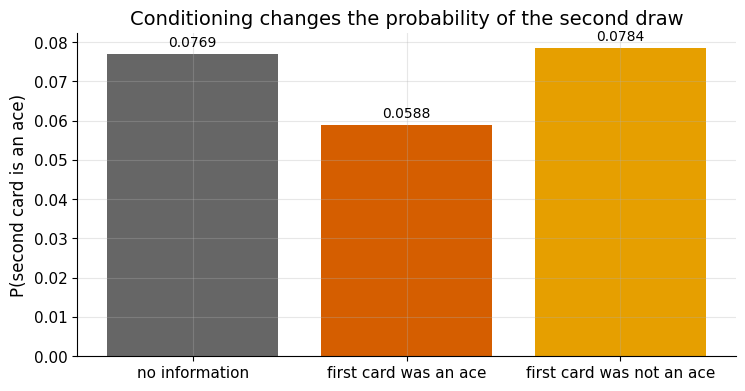

In [5]:
labels = ["no information", "first card was an ace", "first card was not an ace"]
vals = [4 / 52, 3 / 51, 4 / 51]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(labels, vals, color=[NEUTRAL, HIGHLIGHT, SIM])
for i_, v_ in enumerate(vals): ax.text(i_, v_ + 0.002, f"{v_:.4f}", ha="center")
ax.set_ylabel("P(second card is an ace)"); ax.set_title("Conditioning changes the probability of the second draw")
plt.show()
assert np.isclose(4 / 52 * 3 / 51 + 48 / 52 * 4 / 51, 4 / 52)       # total probability: the unconditional chance is unchanged

## 8. 3D visuals

### 8.1 Static: the joint probability of device and purchase
The bar heights are the joint probabilities $P(\text{device}\cap\text{outcome})$ (the 10,000 visits as fractions). Dividing each bar by the total of its device (the sum of the two bars in a row) gives the conditional probabilities of 7.2.

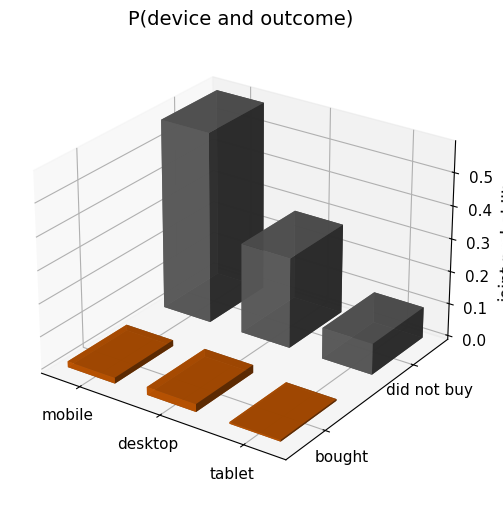

In [6]:
joint = table[["bought", "did not buy"]].to_numpy() / 10000
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
xs, ys = np.meshgrid(range(3), range(2), indexing="ij")
ax.bar3d(xs.ravel() - 0.3, ys.ravel() - 0.3, 0, 0.6, 0.6, joint.ravel(), color=[HIGHLIGHT, NEUTRAL] * 3, alpha=0.9)
ax.set_xticks(range(3)); ax.set_xticklabels(["mobile", "desktop", "tablet"]); ax.set_yticks(range(2)); ax.set_yticklabels(["bought", "did not buy"])
ax.set_zlabel("joint probability"); ax.set_title("P(device and outcome)"); ax.view_init(elev=26, azim=-55)
plt.show()

### 8.2 Interactive Plotly version
Hover to read each joint probability.

In [7]:
fig = go.Figure(go.Surface(x=["bought", "did not buy"], y=["mobile", "desktop", "tablet"], z=joint, colorscale="Viridis"))
fig.update_layout(title="Joint probability of device and purchase", width=700, height=520, scene=dict(xaxis_title="outcome", yaxis_title="device", zaxis_title="probability"))
fig.show()

## 9. Simulation vs theory

### 9.1 Conditional frequency = frequency inside the condition
Generate 1,000,000 simulated visits with the table's joint probabilities, then compute $P(\text{bought}\mid\text{mobile})$ as "among the mobile visits, the share that bought" and compare with the exact $0.03$.

In [8]:
cells = [(d, o) for d in ["mobile", "desktop", "tablet"] for o in ["bought", "did not buy"]]
probs = joint.ravel()
draws = rng.choice(len(cells), size=1_000_000, p=probs)
dev = np.array([cells[i][0] for i in range(len(cells))])[draws]; out = np.array([cells[i][1] for i in range(len(cells))])[draws]
for d in ["mobile", "desktop", "tablet"]:
    print(f"P(bought | {d}) = {np.mean(out[dev == d] == 'bought'):.4f} (exact {table.loc[d, 'bought'] / table.loc[d, 'total']:.4f})")
print(f"P(mobile | bought) = {np.mean(dev[out == 'bought'] == 'mobile'):.4f} (exact {180 / 470:.4f}) | P(mobile) = {np.mean(dev == 'mobile'):.4f}")
assert abs(np.mean(out[dev == "mobile"] == "bought") - 0.03) < 0.002

P(bought | mobile) = 0.0300 (exact 0.0300)
P(bought | desktop) = 0.0798 (exact 0.0800)
P(bought | tablet) = 0.0505 (exact 0.0500)


P(mobile | bought) = 0.3829 (exact 0.3830) | P(mobile) = 0.6002


### 9.2 Draws without replacement
Deal two cards 1,000,000 times: both aces about $1/221=0.00452$ of the time, while *with replacement* it would be $(1/13)^2=0.00592$.

In [9]:
first = rng.integers(0, 52, 1_000_000)                      # card index of the first draw (cards 0 to 3 are the aces)
second = rng.integers(0, 51, 1_000_000); second = second + (second >= first)          # second card: uniform over the 51 that remain
both_aces = np.mean((first < 4) & (second < 4))
second_given_first = np.mean(second[first < 4] < 4)
print(f"P(both aces) = {both_aces:.5f} (exact 1/221 = {1 / 221:.5f}; with replacement {(1 / 13) ** 2:.5f}) | P(second ace | first ace) = {second_given_first:.4f} (exact {3 / 51:.4f})")
assert abs(both_aces - 1 / 221) < 0.0005 and abs(second_given_first - 3 / 51) < 0.004

P(both aces) = 0.00451 (exact 1/221 = 0.00452; with replacement 0.00592) | P(second ace | first ace) = 0.0590 (exact 0.0588)


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
print("conditional rates from a table: table['bought'] / table['total'] ->", (table["bought"] / table["total"]).round(3).to_dict())
chi2, p_value, dof, expected = stats.chi2_contingency(table[["bought", "did not buy"]])
print(f"stats.chi2_contingency: chi-square = {chi2:.1f}, dof = {dof}, p-value = {p_value:.2e}  (small p-value: not independent)")
print("expected counts if device and purchase were independent:\n", pd.DataFrame(expected, index=table.index, columns=["bought", "did not buy"]).round(1))
print("conditional probability by simulation: np.mean(out[dev == 'mobile'] == 'bought') (select the condition first, then average)")
print("pandas: pd.crosstab(dev, out, normalize='index') gives P(outcome | device)")
print(pd.crosstab(dev, out, normalize="index").round(4))

conditional rates from a table: table['bought'] / table['total'] -> {'mobile': 0.03, 'desktop': 0.08, 'tablet': 0.05}
stats.chi2_contingency: chi-square = 111.9, dof = 2, p-value = 5.15e-25  (small p-value: not independent)
expected counts if device and purchase were independent:
          bought  did not buy
mobile    282.0       5718.0
desktop   141.0       2859.0
tablet     47.0        953.0
conditional probability by simulation: np.mean(out[dev == 'mobile'] == 'bought') (select the condition first, then average)
pandas: pd.crosstab(dev, out, normalize='index') gives P(outcome | device)


col_0    bought  did not buy
row_0                       
desktop  0.0798       0.9202
mobile   0.0300       0.9700
tablet   0.0505       0.9495


## 11. Real-world worked examples

---
### Example 1 (main): does the device change who buys? (a contingency table)

**Scenario.** An online store logged **10,000 visits**: 6,000 on **mobile**, 3,000 on **desktop** and 1,000 on **tablet**. The purchases were **180** (mobile), **240** (desktop) and **50** (tablet).

**Questions**
1. What is the overall purchase probability $P(B)$?
2. What is $P(\text{bought}\mid\text{mobile})$, $P(\text{bought}\mid\text{desktop})$ and $P(\text{bought}\mid\text{tablet})$?
3. A purchase is chosen at random. What is the probability that it came from **mobile**, $P(\text{mobile}\mid\text{bought})$? Why is it not the same as $P(\text{bought}\mid\text{mobile})$?
4. Are device and purchase **independent**? Check with the definition and with a chi-square test.

### 11.1 By hand
**Q1.** $P(B)=\dfrac{180+240+50}{10{,}000}=\dfrac{470}{10{,}000}=0.047$.

**Q2.** Restrict to each device: $P(B\mid\text{mobile})=\dfrac{180}{6000}=0.030$; $P(B\mid\text{desktop})=\dfrac{240}{3000}=0.080$; $P(B\mid\text{tablet})=\dfrac{50}{1000}=0.050$.

**Q3.** Restrict to the 470 buyers: $P(\text{mobile}\mid B)=\dfrac{180}{470}=0.383$. Mobile makes up 60 % of visits but only 38 % of purchases. The two conditionals share the numerator 180 but divide by different totals (6,000 visits against 470 buyers), so they are different numbers.

**Q4.** Independence would need $P(B\mid\text{device})=P(B)=0.047$ for every device. We have 0.030, 0.080 and 0.050: **not independent**. Equivalently $P(\text{mobile}\cap B)=0.018$ but $P(\text{mobile})P(B)=0.6\times0.047=0.0282$.

In [11]:
n_visits = 10_000
p_buy = table["bought"].sum() / n_visits
cond = table["bought"] / table["total"]
p_mobile_given_buy = table.loc["mobile", "bought"] / table["bought"].sum()
print(f"Q1: P(bought) = {p_buy:.4f}")
print("Q2:", {d: round(v, 4) for d, v in cond.items()})
print(f"Q3: P(mobile | bought) = {p_mobile_given_buy:.4f} vs P(bought | mobile) = {cond['mobile']:.4f} | share of visits that are mobile {table.loc['mobile', 'total'] / n_visits:.2f}")
print(f"Q4: P(mobile and bought) = {180 / n_visits:.4f} vs P(mobile) P(bought) = {0.6 * p_buy:.4f}")

Q1: P(bought) = 0.0470
Q2: {'mobile': 0.03, 'desktop': 0.08, 'tablet': 0.05}
Q3: P(mobile | bought) = 0.3830 vs P(bought | mobile) = 0.0300 | share of visits that are mobile 0.60
Q4: P(mobile and bought) = 0.0180 vs P(mobile) P(bought) = 0.0282


### 11.2 In code with `scipy`, and the asserts

In [12]:
assert np.isclose(p_buy, 0.047) and np.allclose(cond.values, [0.03, 0.08, 0.05]) and np.isclose(p_mobile_given_buy, 180 / 470)
assert not np.isclose(180 / n_visits, 0.6 * p_buy)
chi2, p_value, dof, expected = stats.chi2_contingency(table[["bought", "did not buy"]], correction=False)
print(f"chi-square = {chi2:.1f}, degrees of freedom = {dof}, p-value = {p_value:.2e}")
assert p_value < 1e-10 and dof == 2
# law of total probability preview: the overall rate is the average of the conditional rates weighted by the device mix
assert np.isclose(sum(cond[d] * table.loc[d, "total"] / n_visits for d in table.index), p_buy)
print("all checks passed")

chi-square = 111.9, degrees of freedom = 2, p-value = 5.15e-25
all checks passed


### 11.3 Verify by simulation
Simulate 1,000,000 visits from the joint table (Section 9.1 did this) and compare, then check the chi-square test by shuffling the outcomes: independence should give a much smaller statistic.

In [13]:
print(f"simulated P(bought) = {np.mean(out == 'bought'):.4f} | P(bought | desktop) = {np.mean(out[dev == 'desktop'] == 'bought'):.4f} | P(mobile | bought) = {np.mean(dev[out == 'bought'] == 'mobile'):.4f}")
shuffled = rng.permutation(out)                                  # breaking the link between device and outcome makes them independent
ct_real = pd.crosstab(dev, out); ct_shuf = pd.crosstab(dev, shuffled)
print(f"chi-square on the real simulated data: {stats.chi2_contingency(ct_real)[0]:.0f} | after shuffling the outcomes: {stats.chi2_contingency(ct_shuf)[0]:.2f}")
assert stats.chi2_contingency(ct_real)[0] > 1000 and stats.chi2_contingency(ct_shuf)[0] < 15

simulated P(bought) = 0.0470 | P(bought | desktop) = 0.0798 | P(mobile | bought) = 0.3829


chi-square on the real simulated data: 11133 | after shuffling the outcomes: 0.19


### 11.4 Plots with the regions shaded

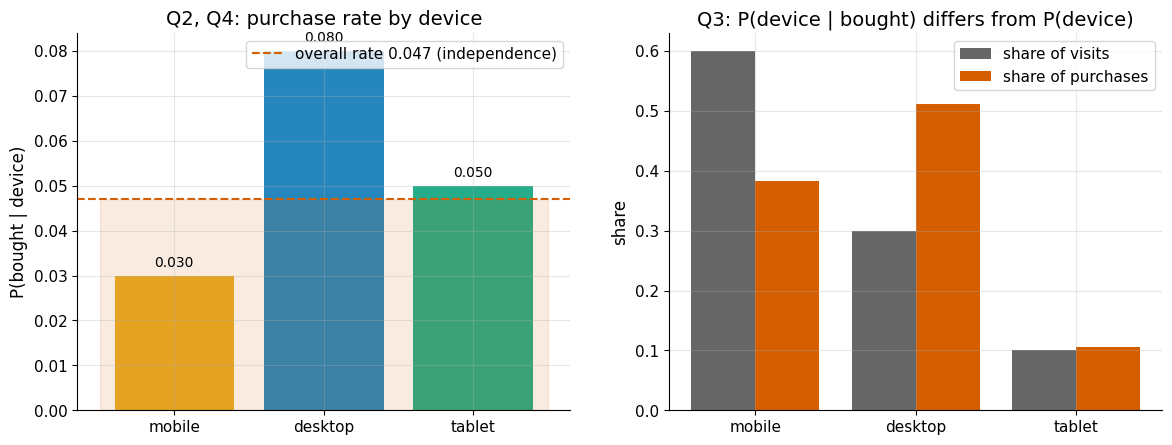

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
axes[0].bar(cond.index, cond.values, color=[SIM, MAIN, COLORS[2]], alpha=0.85); axes[0].axhline(p_buy, color=HIGHLIGHT, linestyle="--", label=f"overall rate {p_buy:.3f} (independence)")
axes[0].fill_between([-0.5, 2.5], 0, p_buy, color=HIGHLIGHT, alpha=0.12)
for i_, v_ in enumerate(cond.values): axes[0].text(i_, v_ + 0.002, f"{v_:.3f}", ha="center")
axes[0].set_ylabel("P(bought | device)"); axes[0].set_title("Q2, Q4: purchase rate by device"); axes[0].legend()
share_visit = table["total"] / n_visits; share_buy = table["bought"] / table["bought"].sum()
xx = np.arange(3); axes[1].bar(xx - 0.2, share_visit, 0.4, color=NEUTRAL, label="share of visits"); axes[1].bar(xx + 0.2, share_buy, 0.4, color=HIGHLIGHT, label="share of purchases")
axes[1].set_xticks(xx); axes[1].set_xticklabels(table.index); axes[1].set_ylabel("share"); axes[1].set_title("Q3: P(device | bought) differs from P(device)"); axes[1].legend()
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **Device matters.** The overall purchase rate is **4.7 %**, but it is **3 % on mobile, 8 % on desktop and 5 % on tablet**. Under independence all three would equal 4.7 %.
- **Two different questions.** $P(\text{bought}\mid\text{mobile})=3\,\%$ is small, yet $P(\text{mobile}\mid\text{bought})=38.3\,\%$ is much larger; the second shares the numerator 180 but divides by the 470 buyers, not by the 6,000 mobile visits. Mobile is 60 % of visits and only 38 % of purchases.
- **The test agrees.** The chi-square statistic is **111.9** (2 degrees of freedom, $p\approx5\times10^{-25}$): the expected counts under independence (282 mobile buyers, 141 desktop buyers) are far from the observed 180 and 240. In the simulation the statistic is 11,133 for the real data and 1.3 after shuffling the outcomes, which breaks the link.
- **Decision.** Desktop visitors convert 2.7 times as often as mobile visitors, and mobile is the biggest group: improving the mobile checkout (say from 3 % to 4 %) would add about 60 purchases per 10,000 visits, more than any other single device change.

---
### Example 2: the Monty Hall problem

**Scenario.** A game show has 3 doors: a car behind one, goats behind two. You pick door 1. The host, who knows where the car is, always opens a *different* door with a goat, and offers you the choice to **stay** or **switch** to the remaining door. Which is better?

### 11.6 By hand, in code and by simulation
**By hand.** Before any door is opened the car is equally likely behind each door: $\tfrac13$ each. Your pick wins if the car is behind door 1: $\tfrac13$. The host's action does not change that (he *always* can open a goat door), so the probability that the car is behind the other unopened door is the rest, $\mathbf{\tfrac23}$. **Switching wins whenever your first pick was wrong**, which happens $\tfrac23$ of the time.

stay: 0.3349 (exact 1/3) | switch: 0.6677 (exact 2/3)
enumeration: {'stay': 0.3333333333333333, 'switch': 0.6666666666666666}


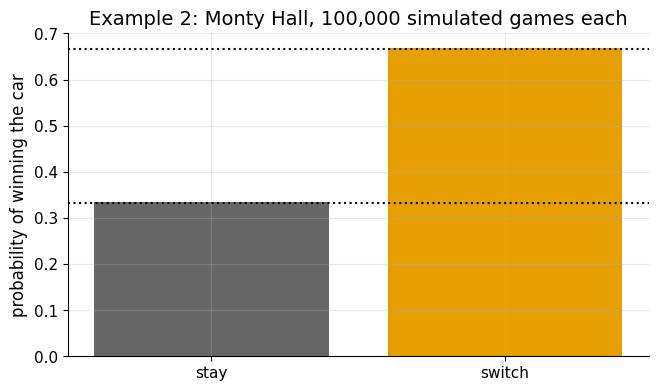

In [15]:
def play(strategy, n_games, gen):
    car = gen.integers(0, 3, n_games); pick = gen.integers(0, 3, n_games)
    wins = 0
    for c, p_ in zip(car, pick):
        goat_doors = [d for d in range(3) if d != p_ and d != c]          # doors the host may open
        opened = gen.choice(goat_doors)
        final = p_ if strategy == "stay" else next(d for d in range(3) if d not in (p_, opened))
        wins += final == c
    return wins / n_games
mh = np.random.default_rng(10)
stay, switch = play("stay", 100_000, mh), play("switch", 100_000, mh)
print(f"stay: {stay:.4f} (exact 1/3) | switch: {switch:.4f} (exact 2/3)")
assert abs(stay - 1 / 3) < 0.006 and abs(switch - 2 / 3) < 0.006
# the same answer by enumerating the 3 equally likely car positions for a fixed pick (door 1)
by_hand = {"stay": sum(c == 0 for c in range(3)) / 3, "switch": sum(c != 0 for c in range(3)) / 3}
print("enumeration:", by_hand)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(["stay", "switch"], [stay, switch], color=[NEUTRAL, SIM]); ax.axhline(1 / 3, color="black", linestyle=":"); ax.axhline(2 / 3, color="black", linestyle=":")
ax.set_ylabel("probability of winning the car"); ax.set_title("Example 2: Monty Hall, 100,000 simulated games each")
plt.show()

### 11.6b Interpretation and decision (Example 2)
- Over 100,000 simulated games each, **staying wins 33.5 %** of the time and **switching wins 66.8 %**, matching 1/3 and 2/3.
- The intuition "two doors left, so 50-50" fails because the two doors are **not symmetric**: your door was chosen before the host acted, while the other door survived the host's *informed* choice. Information was added, so the probabilities moved to the door the host avoided.
- **Decision.** Always switch (if the host's rule is as stated). The answer would be 1/2 if the host opened a door at random and happened to show a goat.

---
### Example 3: the two-children puzzle (the wording changes the answer)

**Scenario.** A family has two children; each is a boy or a girl with probability $\tfrac12$, independently. (a) You learn that **at least one is a boy**. What is the probability that both are boys? (b) You learn that **the older child is a boy**. Now what is the probability that both are boys?

### 11.7 By hand, in code and by simulation
**By hand.** The four equally likely families (older, younger): BB, BG, GB, GG. (a) "At least one boy" removes GG, leaving BB, BG, GB: $P(BB\mid\text{at least one boy})=\tfrac13$. (b) "Older is a boy" leaves BB, BG: $P(BB\mid\text{older is a boy})=\tfrac12$.

(a) P(both boys | at least one boy) = 0.3333 | (b) P(both boys | older is a boy) = 0.5000
simulated: (a) 0.3342 | (b) 0.5006


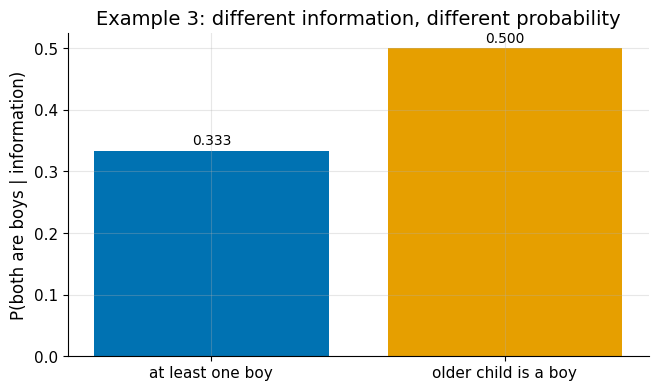

In [16]:
families = list(itertools.product("BG", repeat=2))                         # (older, younger)
at_least_one_boy = [f for f in families if "B" in f]; older_boy = [f for f in families if f[0] == "B"]
pa = sum(f == ("B", "B") for f in at_least_one_boy) / len(at_least_one_boy); pb = sum(f == ("B", "B") for f in older_boy) / len(older_boy)
print(f"(a) P(both boys | at least one boy) = {pa:.4f} | (b) P(both boys | older is a boy) = {pb:.4f}")
kids = np.random.default_rng(12).integers(0, 2, size=(400_000, 2))          # 1 = boy
sim_a = np.mean((kids[kids.any(axis=1)] == 1).all(axis=1)); sim_b = np.mean(kids[kids[:, 0] == 1][:, 1] == 1)
print(f"simulated: (a) {sim_a:.4f} | (b) {sim_b:.4f}")
assert np.isclose(pa, 1 / 3) and np.isclose(pb, 1 / 2) and abs(sim_a - 1 / 3) < 0.005 and abs(sim_b - 1 / 2) < 0.005
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(["at least one boy", "older child is a boy"], [pa, pb], color=[MAIN, SIM]); ax.set_ylabel("P(both are boys | information)"); ax.set_title("Example 3: different information, different probability")
for i_, v_ in enumerate([pa, pb]): ax.text(i_, v_ + 0.01, f"{v_:.3f}", ha="center")
plt.show()

### 11.7b Interpretation and decision (Example 3)
- "At least one is a boy" leaves three equally likely families (BB, BG, GB), so the answer is **1/3**; "the older child is a boy" leaves two (BB, BG), so it is **1/2**. Simulation gives 0.334 and 0.501.
- The two statements sound alike but carry different information, and probability responds to **exactly what you were told**.
- **Decision.** When a conditional-probability question seems paradoxical, list the equally likely cases, cross out those the information rules out, and count what remains.

## 12. Where it is used

### Statistics
- **Conditional distributions** (the distribution of $Y$ given $X=x$) are the basis of regression, the conditional mean $E[Y\mid X]$ and **likelihood** ($P(\text{data}\mid\text{parameter})$).
- **Tests of independence** (chi-square on a contingency table, Example 1) and **relative risk / odds ratio** compare conditional probabilities (05_06).

### Data science
- **Conversion rates by segment** ($P(\text{buy}\mid\text{device})$), funnels (each step conditional on the previous), **churn by cohort**, **conditional click-through rates**.
- **Simpson's paradox** (an aggregate trend reverses inside the groups) is a warning that conditioning on a variable can change the conclusion.

### ML and AI
- **Classifiers estimate $P(\text{class}\mid\text{features})$;** language models multiply conditionals $P(w_t\mid w_1,\dots,w_{t-1})$ (the chain rule of 5.2); **naive Bayes** assumes the features are conditionally independent given the class.
- **Precision, recall and calibration** are conditional probabilities ($P(\text{truly positive}\mid\text{predicted positive})$ and its mirror $P(\text{predicted positive}\mid\text{truly positive})$), which is why they differ (0a_05).

## 13. Common pitfalls and misconceptions

- **Confusing $P(A\mid B)$ with $P(B\mid A)$** (the prosecutor's fallacy): "most mobile visitors do not buy" is not "most buyers are not on mobile".
- **Ignoring the base rate:** a conditional probability depends on the sizes of the groups; always check how big the condition is.
- **Treating draws without replacement as independent:** the second card depends on the first (5.3).
- **Mutually exclusive is not independent:** exclusive events with positive probability are maximally dependent.
- **The exact wording of the information matters:** "at least one boy" and "the older is a boy" give $\tfrac13$ and $\tfrac12$ (Example 3).
- **Monty Hall relies on the host's rule:** he *knows* and *must* open a goat door; if he opened a door at random the answer would change.
- **Conditioning on a consequence** (selection effects, "survivors") can create fake patterns; ask who is in the condition.
- **Zero probability condition:** $P(A\mid B)$ is undefined if $P(B)=0$.

## 14. Exercises

1. Two dice are rolled. Find $P(\text{sum}=7\mid\text{first die}=3)$ and $P(\text{first die}=3\mid\text{sum}=7)$. Are "sum is 7" and "first die is 3" independent?
2. A box has 6 red and 4 blue balls. Two are drawn without replacement. Find $P(\text{both red})$, $P(\text{second is blue})$ and $P(\text{second blue}\mid\text{first red})$.
3. In a company 60 % of employees are in engineering, and 30 % of engineers and 50 % of non-engineers work remotely. Build the joint table and find $P(\text{engineer}\mid\text{remote})$.
4. The probability that it rains on a random day is 0.2. When it rains, a bus is late with probability 0.5; when it does not rain, 0.1. What is $P(\text{late})$ and $P(\text{rain}\mid\text{late})$? (Hint: build the four joint probabilities.)
5. Show that if $A$ and $B$ are independent then $A$ and $B^c$ are also independent.
6. (Harder) Monty Hall with **4 doors**: you pick one, the host opens one goat door among the other three, and you may switch to one of the **two** remaining doors chosen at random. What is the probability of winning by staying and by switching to a random remaining door? Verify by simulation.

Solutions are at the end.

## 15. Summary table

| Idea | Formula | Remember |
|---|---|---|
| Conditional probability | $P(A\mid B)=P(A\cap B)/P(B)$ | shrink the world to $B$ |
| Multiplication rule | $P(A\cap B)=P(B)P(A\mid B)$ | chain for several events |
| Independence | $P(A\mid B)=P(A)$ | the same as $P(A\cap B)=P(A)P(B)$ |
| Reverse conditional | $P(B\mid A)\neq P(A\mid B)$ | different denominators (Bayes, 0a_05) |
| Without replacement | $\frac{4}{52}\cdot\frac{3}{51}$ | each draw changes the deck |
| Mutually exclusive | $P(A\mid B)=0$ | dependent, not independent |
| Chi-square test | `stats.chi2_contingency` | small p-value: not independent |

## Solutions

In [17]:
print(f"1: P(sum 7 | first = 3) = {1 / 6:.4f} (only (3,4) works among 6) | P(first = 3 | sum 7) = {1 / 6:.4f} | P(sum 7) = {6 / 36:.4f}: equal to P(sum 7 | first = 3) so they ARE independent")
p_rr = 6 / 10 * 5 / 9; p_second_blue = 6 / 10 * 4 / 9 + 4 / 10 * 3 / 9
print(f"2: P(both red) = {p_rr:.4f} | P(second blue) = {p_second_blue:.4f} | P(second blue | first red) = {4 / 9:.4f}")
eng, remote_e, remote_n = 0.6, 0.3, 0.5
joint_e = eng * remote_e; joint_n = (1 - eng) * remote_n
print(f"3: P(remote) = {joint_e + joint_n:.2f} | P(engineer | remote) = {joint_e / (joint_e + joint_n):.4f}")
pl = 0.2 * 0.5 + 0.8 * 0.1
print(f"4: P(late) = {pl:.2f} | P(rain | late) = {0.2 * 0.5 / pl:.4f}")
print("5: P(A and not B) = P(A) - P(A and B) = P(A) - P(A) P(B) = P(A) (1 - P(B)) = P(A) P(not B)")
g = np.random.default_rng(14); N6 = 200_000
car = g.integers(0, 4, N6); pick = g.integers(0, 4, N6); stay6 = (car == pick).mean()
sw = 0
for c, p_ in zip(car[:60_000], pick[:60_000]):
    opened = g.choice([d for d in range(4) if d != p_ and d != c]); remaining = [d for d in range(4) if d not in (p_, opened)]
    sw += g.choice(remaining) == c
print(f"6: stay {stay6:.4f} (exact 1/4) | switch to a random remaining door {sw / 60_000:.4f} (exact 3/8 = {3 / 8:.4f})")

1: P(sum 7 | first = 3) = 0.1667 (only (3,4) works among 6) | P(first = 3 | sum 7) = 0.1667 | P(sum 7) = 0.1667: equal to P(sum 7 | first = 3) so they ARE independent
2: P(both red) = 0.3333 | P(second blue) = 0.4000 | P(second blue | first red) = 0.4444
3: P(remote) = 0.38 | P(engineer | remote) = 0.4737
4: P(late) = 0.18 | P(rain | late) = 0.5556
5: P(A and not B) = P(A) - P(A and B) = P(A) - P(A) P(B) = P(A) (1 - P(B)) = P(A) P(not B)


6: stay 0.2511 (exact 1/4) | switch to a random remaining door 0.3736 (exact 3/8 = 0.3750)


**1.** $P(\text{sum}=7\mid\text{first}=3)=\tfrac16$ (only $(3,4)$ among six second-die values) and $P(\text{first}=3\mid\text{sum}=7)=\tfrac16$ (one of the six ways to make 7). Since $P(\text{sum}=7)=\tfrac16$ too, the two events **are independent**: whatever the first die shows there is exactly one second-die value that makes 7.

**2.** $P(\text{both red})=\tfrac6{10}\cdot\tfrac59=\tfrac13$. $P(\text{second blue})=\tfrac6{10}\cdot\tfrac49+\tfrac4{10}\cdot\tfrac39=0.4$ (the same as for the first draw, by symmetry). $P(\text{second blue}\mid\text{first red})=\tfrac49=0.444$.

**3.** Joint probabilities: engineer and remote $0.6\times0.3=0.18$; non-engineer and remote $0.4\times0.5=0.20$. So $P(\text{remote})=0.38$ and $P(\text{engineer}\mid\text{remote})=0.18/0.38=\mathbf{0.474}$ (although engineers are 60 % of the staff, they are only 47 % of the remote workers).

**4.** $P(\text{late})=0.2\times0.5+0.8\times0.1=\mathbf{0.18}$. $P(\text{rain}\mid\text{late})=0.1/0.18=\mathbf{0.556}$.

**5.** $P(A\cap B^c)=P(A)-P(A\cap B)=P(A)-P(A)P(B)=P(A)\,(1-P(B))=P(A)\,P(B^c)$, which is the definition of independence for $A$ and $B^c$.

**6.** Staying wins with probability $\tfrac14$. After the host opens one goat door, the car is behind one of the other two remaining doors with probability $\tfrac34$ in total; choosing one of them at random wins $\tfrac12\times\tfrac34=\mathbf{\tfrac38=0.375}$ (simulation: stay 0.251, switch 0.374). Switching to a *random* door is better than staying, but less so than in the 3-door game.